Output directory: /content/project_output
✅ Dataset created: (1200, 12)


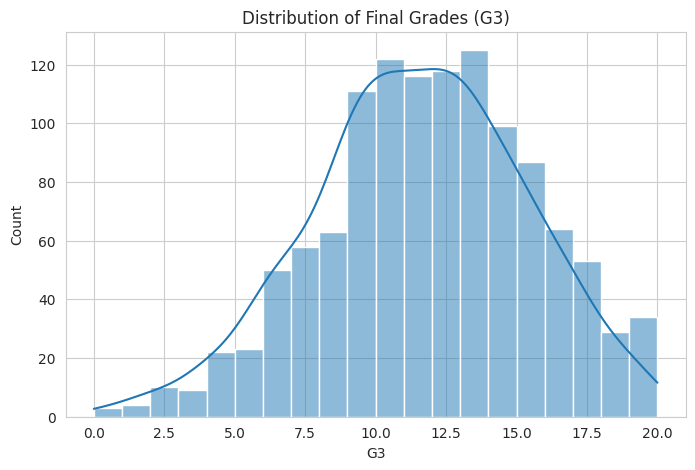

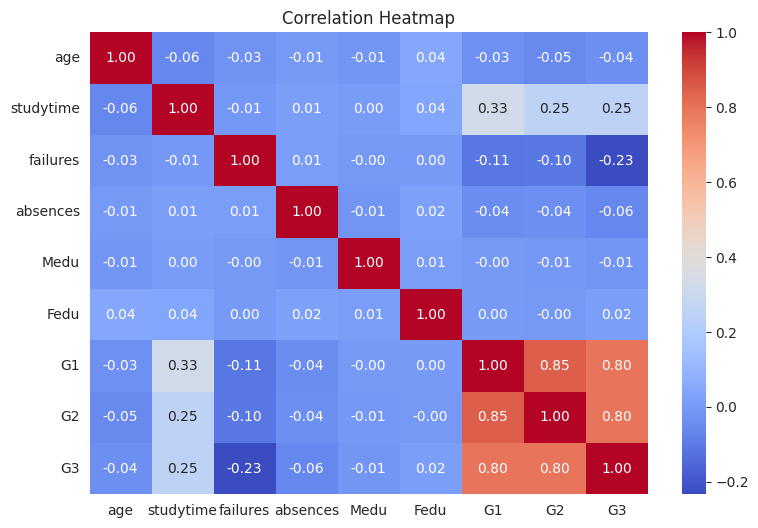

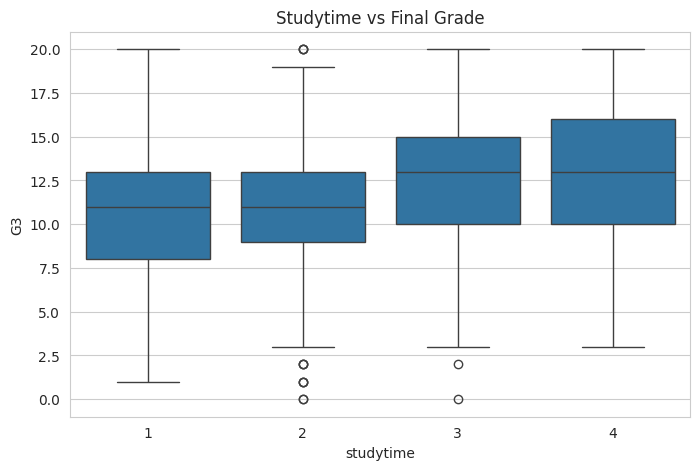

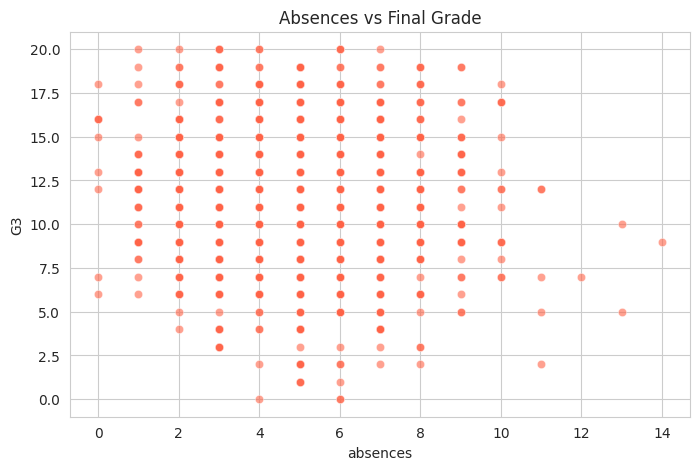

✅ Preprocessing complete. Feature count: 15
✅ Models trained successfully.
               RMSE    MAE     R2
Linear        2.178  1.711  0.716
Ridge         2.178  1.711  0.716
Lasso         2.201  1.736  0.710
RandomForest  2.352  1.828  0.669


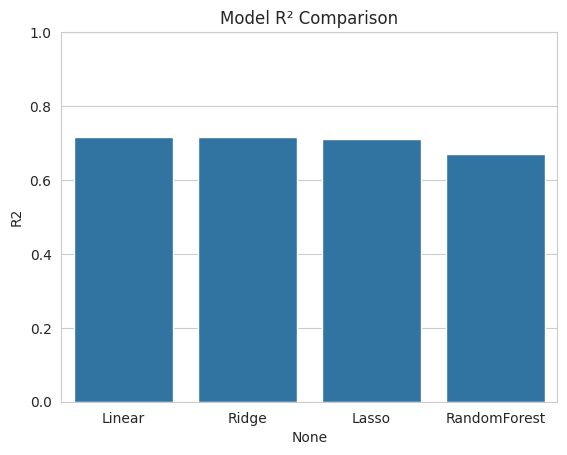

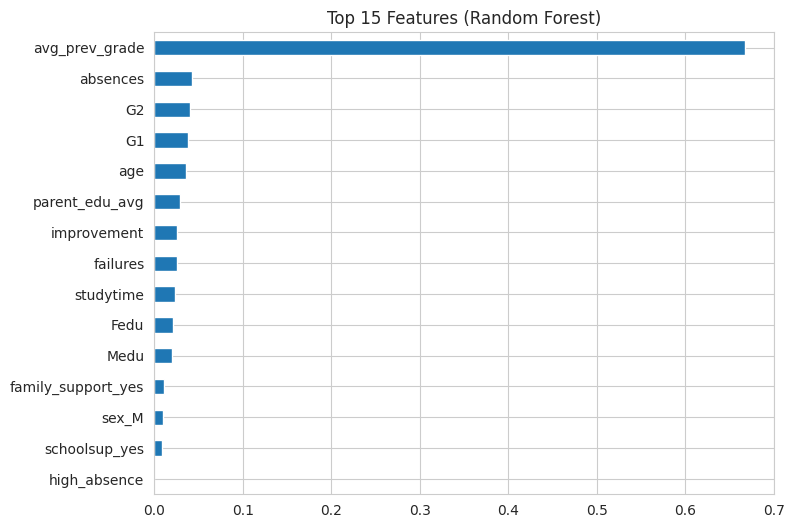

/tmp/ipython-input-3578172750.py:135: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_sample)


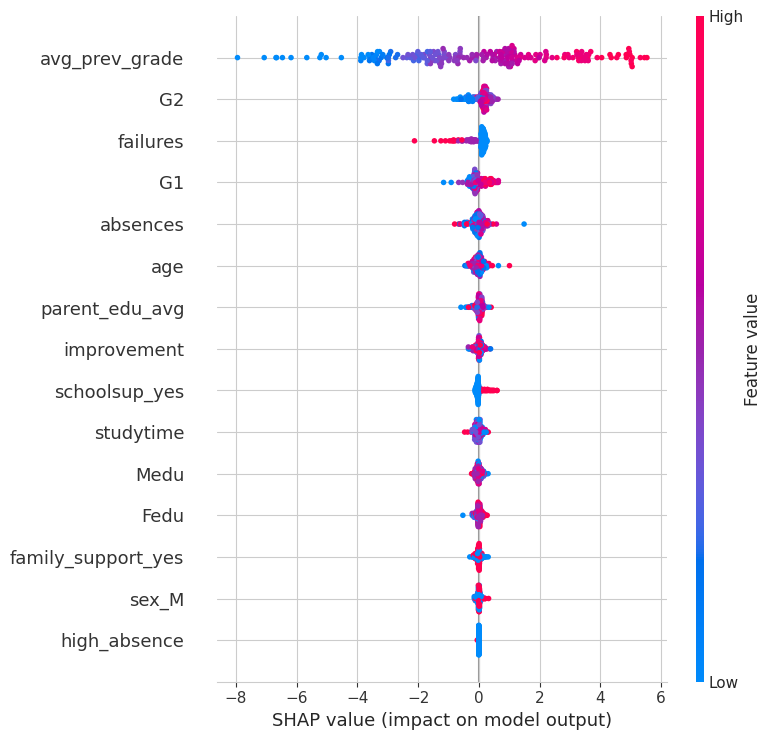

✅ Sample Predictions:


,Actual,Predicted
1178,15.0,14.015
865,14.0,14.785
101,12.0,12.255
439,12.0,11.465
58,17.0,14.535


Results saved: /content/project_output/sample_predictions.csv
📄 Word report saved: /content/project_output/Student_Academic_Performance_Report.docx


In [2]:
# ============================================================
# STUDENT ACADEMIC PERFORMANCE PREDICTION
# ============================================================

# Install all dependencies
!pip install --quiet python-docx shap joblib seaborn scikit-learn matplotlib pandas numpy

# ------------------------------------------------------------
# 1. IMPORTS & INITIAL SETUP
# ------------------------------------------------------------
import os, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import shap

sns.set_style('whitegrid')
np.random.seed(42)

OUTDIR = '/content/project_output'
IMGDIR = os.path.join(OUTDIR, 'project_images')
os.makedirs(IMGDIR, exist_ok=True)
print("Output directory:", OUTDIR)

# ------------------------------------------------------------
# 2. DATA GENERATION (≈1200 students)
# ------------------------------------------------------------
n = 1200
df = pd.DataFrame({
    'age': np.random.randint(15,22,n),
    'sex': np.random.choice(['M','F'],n,p=[.48,.52]),
    'studytime': np.random.choice([1,2,3,4],n,p=[.25,.4,.25,.1]),
    'failures': np.random.choice([0,1,2,3],n,p=[.8,.12,.06,.02]),
    'absences': np.random.poisson(5,n),
    'Medu': np.random.choice([0,1,2,3,4],n,p=[.05,.1,.3,.35,.2]),
    'Fedu': np.random.choice([0,1,2,3,4],n,p=[.05,.1,.3,.35,.2]),
    'family_support': np.random.choice(['yes','no'],n,p=[.7,.3]),
    'schoolsup': np.random.choice(['yes','no'],n,p=[.15,.85])
})
df['G1'] = np.clip(np.random.normal(10+1.2*df.studytime-0.6*df.failures-0.03*df.absences,3),0,20).round()
df['G2'] = np.clip(df.G1 + np.random.normal(0.5,2,n),0,20).round()
df['G3'] = np.clip(0.4*df.G1 + 0.5*df.G2 + np.random.normal(0.5-0.8*df.failures-0.05*df.absences,2),0,20).round()
df.to_csv(os.path.join(OUTDIR,'student_data.csv'), index=False)
print("✅ Dataset created:", df.shape)

# ------------------------------------------------------------
# 3. VISUAL EDA
# ------------------------------------------------------------
plt.figure(figsize=(8,5))
sns.histplot(df['G3'], bins=20, kde=True)
plt.title('Distribution of Final Grades (G3)')
plt.savefig(f"{IMGDIR}/hist_g3.png"); plt.show()

plt.figure(figsize=(9,6))
sns.heatmap(df.select_dtypes(np.number).corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Heatmap'); plt.savefig(f"{IMGDIR}/corr.png"); plt.show()

plt.figure(figsize=(8,5))
sns.boxplot(x='studytime', y='G3', data=df)
plt.title('Studytime vs Final Grade')
plt.savefig(f"{IMGDIR}/box_studytime.png"); plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(x='absences', y='G3', data=df, alpha=0.6, color='tomato')
plt.title('Absences vs Final Grade')
plt.savefig(f"{IMGDIR}/scatter_abs.png"); plt.show()

# ------------------------------------------------------------
# 4. PREPROCESSING & FEATURE ENGINEERING
# ------------------------------------------------------------
df['avg_prev_grade'] = (df['G1'] + df['G2']) / 2
df['improvement'] = df['G2'] - df['G1']
df['high_absence'] = (df['absences'] > 10).astype(int)
df['parent_edu_avg'] = (df['Medu'] + df['Fedu']) / 2

df_enc = pd.get_dummies(df, drop_first=True)
X = df_enc.drop('G3', axis=1)
y = df_enc['G3']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

joblib.dump(scaler, os.path.join(OUTDIR,'scaler.joblib'))
joblib.dump(X.columns.tolist(), os.path.join(OUTDIR,'feature_list.joblib'))
print("✅ Preprocessing complete. Feature count:", X.shape[1])

# ------------------------------------------------------------
# 5. MODEL TRAINING
# ------------------------------------------------------------
lr = LinearRegression().fit(X_train_s, y_train)
ridge_cv = GridSearchCV(Ridge(), {'alpha':[0.01,0.1,1,5]}, cv=5, scoring='r2', n_jobs=-1).fit(X_train_s, y_train)
lasso_cv = GridSearchCV(Lasso(max_iter=10000), {'alpha':[0.001,0.01,0.1,1]}, cv=5, scoring='r2', n_jobs=-1).fit(X_train_s, y_train)
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1).fit(X_train, y_train)

print("✅ Models trained successfully.")

# ------------------------------------------------------------
# 6. EVALUATION
# ------------------------------------------------------------
def eval_metrics(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true,y_pred)), mean_absolute_error(y_true,y_pred), r2_score(y_true,y_pred)

res = {
    'Linear': eval_metrics(y_test, lr.predict(X_test_s)),
    'Ridge': eval_metrics(y_test, ridge_cv.best_estimator_.predict(X_test_s)),
    'Lasso': eval_metrics(y_test, lasso_cv.best_estimator_.predict(X_test_s)),
    'RandomForest': eval_metrics(y_test, rf.predict(X_test))
}
res_df = pd.DataFrame(res, index=['RMSE','MAE','R2']).T.round(3)
print(res_df)

sns.barplot(x=res_df.index, y=res_df['R2'])
plt.title('Model R² Comparison'); plt.ylim(0,1)
plt.savefig(f"{IMGDIR}/model_r2.png"); plt.show()

res_df.to_csv(f"{OUTDIR}/model_performance.csv")

# ------------------------------------------------------------
# 7. FEATURE IMPORTANCE & SHAP
# ------------------------------------------------------------
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8,6))
imp.head(15).plot(kind='barh'); plt.gca().invert_yaxis()
plt.title('Top 15 Features (Random Forest)')
plt.savefig(f"{IMGDIR}/feature_importances.png"); plt.show()

# SHAP Summary
explainer = shap.TreeExplainer(rf)
X_sample = X_train.sample(200, random_state=42)
shap_values = explainer.shap_values(X_sample)
shap.summary_plot(shap_values, X_sample)

# ------------------------------------------------------------
# 8. FIXED INFERENCE (NO FEATURE-NAME ERROR)
# ------------------------------------------------------------
sample = X_test.iloc[:5, :].copy()
preds = rf.predict(sample)
result_df = sample.copy()
result_df['Actual'] = y_test.iloc[:5].values
result_df['Predicted'] = preds
print("✅ Sample Predictions:")
display(result_df[['Actual','Predicted']])

result_df.to_csv(os.path.join(OUTDIR,'sample_predictions.csv'), index=False)
print("Results saved:", os.path.join(OUTDIR,'sample_predictions.csv'))

# ------------------------------------------------------------
# 9. OPTIONAL: WORD REPORT GENERATION
# ------------------------------------------------------------
from docx import Document
from docx.shared import Inches, Pt
doc = Document()
doc.add_heading('STUDENT ACADEMIC PERFORMANCE PREDICTION',0)
doc.add_paragraph('(Generated automatically using Colab Notebook)')
doc.add_heading('Model Evaluation', level=1)
doc.add_paragraph(str(res_df))
for img in ['hist_g3.png','corr.png','box_studytime.png','scatter_abs.png','model_r2.png','feature_importances.png']:
    pth = os.path.join(IMGDIR,img)
    if os.path.exists(pth): doc.add_picture(pth,width=Inches(6))
output_doc = os.path.join(OUTDIR,'Student_Academic_Performance_Report.docx')
doc.save(output_doc)
print("📄 Word report saved:", output_doc)
